# Análise bivariada e evidências para as transformações

Continuação da limpeza (`Limpeza/Limpeza_V2.ipynb`). Usa o `UCMF_limpo.csv` (resultado da limpeza) e o `UCMF_raw.csv` (dado original) para:

1. comparar FC e IDADE antes e depois da limpeza;
2. analisar cada variável contra o alvo `NORMAL X ANORMAL`;
3. verificar se a relação entre FC e alvo é explicada pela idade;
4. reunir as evidências que justificam as transformações da modelagem.

**Um único teste para todas as variáveis: qui-quadrado (α = 0,05).** As numéricas são divididas em quartis, e todas as variáveis ganham o mesmo resumo de efeito (% de Anormal na categoria ou faixa de maior vs menor proporção), comparável numa só tabela.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency, spearmanr

pd.set_option('display.max_colwidth', None)

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'UCMF_raw.csv').exists())
PASTA = RAIZ / 'Análise Bivariada'
FIG = PASTA / 'figuras'   
TAB = PASTA / 'tabelas'   
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(RAIZ / 'UCMF_raw.csv')
df_limpo = pd.read_csv(RAIZ / 'Limpeza' / 'UCMF_limpo.csv')

ALVO = 'NORMAL X ANORMAL'
ALFA = 0.05
# Categoria (ou faixa) com menos de 30 registros não entra no resumo do efeito: com
# tão poucos casos, a % de Anormal oscila demais para ser comparada.
N_MIN = 30

# Mesmas faixas etárias da limpeza (etapa 4.1), para os resultados serem comparáveis.
FAIXAS = [0, 1, 5, 10, 15, 21]
ROTULOS_FAIXAS = ['0–1', '1–5', '5–10', '10–15', '15–21']
faixa_etaria = pd.cut(df_limpo['IDADE'], bins=FAIXAS, labels=ROTULOS_FAIXAS, include_lowest=True)

print(f'df_raw: {df_raw.shape} | df_limpo: {df_limpo.shape}')

df_raw: (12873, 21) | df_limpo: (10603, 51)


In [ ]:
COR = {'Normal': '#2a78d6', 'Anormal': '#eb6834'}
COR_UNICA = COR['Normal']                     # figuras com uma única série
TINTA, TINTA_2, GRADE, EIXO = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.titlesize': 14,
    'text.color': TINTA, 'axes.labelcolor': TINTA, 'axes.titlecolor': TINTA,
    'axes.edgecolor': EIXO, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
})


def salvar(fig, nome):
    fig.savefig(FIG / f'{nome}.png', dpi=300, bbox_inches='tight')
    plt.show()


def exportar(tabela, nome):
    tabela.to_csv(TAB / f'{nome}.csv', index=False, encoding='utf-8-sig')

def num(x, casas=1):
    return f'{x:.{casas}f}'.replace('.', ',')


def fmt_n(n):
    return f'{int(n):,}'.replace(',', '.')


def fmt_p(p):
    return '< 0,001' if p < 0.001 else num(p, 3)


def p_txt(p):
    """p-valor para usar dentro de frases: 'p < 0,001' ou 'p = 0,234'."""
    return 'p < 0,001' if p < 0.001 else f'p = {num(p, 3)}'

In [ ]:
# MOTIVO1 virou colunas binárias na limpeza (etapa 7). Para analisá-lo como uma variável
# só, reconstruímos a categoria a partir das 5 colunas que vieram dele: cada linha tem
# no máximo uma delas marcada; sem nenhuma, o motivo não foi registrado (NaN, como os
# ausentes das outras variáveis).
COLS_MOTIVO1 = {
    'motivo_parecer_cardiologico': 'Parecer cardiológico',
    'motivo_suspeita_de_cardiopatia': 'Suspeita de cardiopatia',
    'motivo_cardiopatia_ja_estabelecida': 'Cardiopatia já estabelecida',
    'motivo_check_up': 'Check-up',
    'motivo_outro': 'Outro',
}
marcados = df_limpo[list(COLS_MOTIVO1)]
assert marcados.sum(axis=1).max() == 1, 'linha com mais de um MOTIVO1'
MOTIVO1 = marcados.idxmax(axis=1).map(COLS_MOTIVO1).where(marcados.sum(axis=1) == 1).rename('MOTIVO1')

# Só a PPA recalculada existe no df_limpo. A ordem clínica é mantida nas tabelas.
PPA = pd.Categorical(df_limpo['PPA_calc'],
                     categories=['Normal', 'Pré-hipertensão', 'HAS estágio 1', 'HAS estágio 2'],
                     ordered=True)
PPA = pd.Series(PPA, index=df_limpo.index, name='PPA')

print(MOTIVO1.value_counts(dropna=False).to_string())

MOTIVO1
Parecer cardiológico           4811
Suspeita de cardiopatia        3807
Cardiopatia já estabelecida     993
Check-up                        626
Outro                           266
NaN                             100


## Parte 1 – FC x IDADE, antes e depois da limpeza

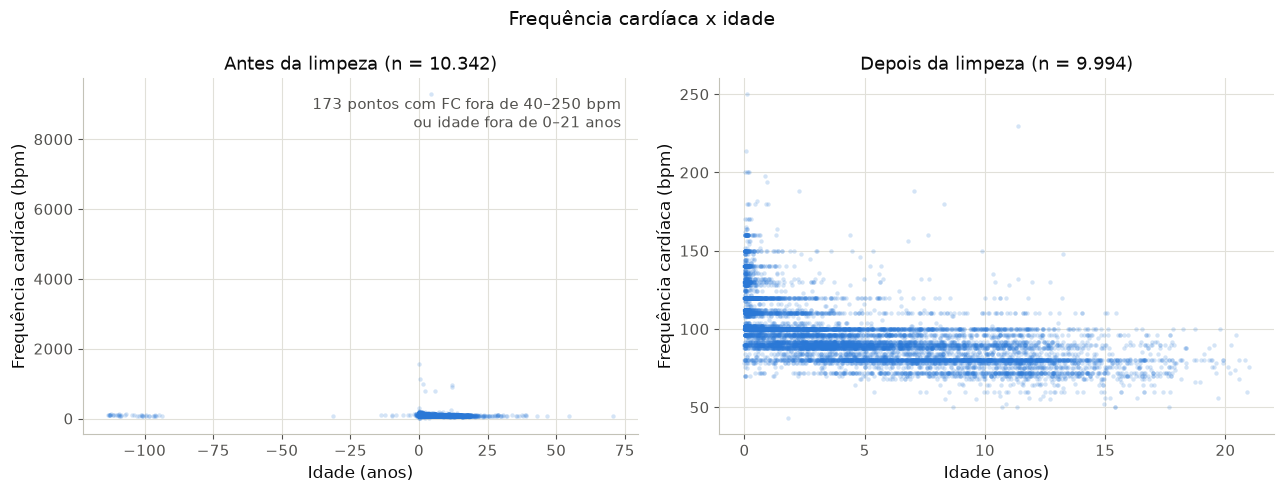

In [ ]:

fc_bruta = pd.to_numeric(df_raw['FC'], errors='coerce')
idade_bruta = pd.to_numeric(df_raw['IDADE'], errors='coerce')
tem_bruto = fc_bruta.notna() & idade_bruta.notna()
fora_faixa = tem_bruto & (~fc_bruta.between(40, 250) | ~idade_bruta.between(0, 21))
tem_limpo = df_limpo['FC'].notna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(idade_bruta[tem_bruto], fc_bruta[tem_bruto], s=10, alpha=0.2, color=COR_UNICA, linewidths=0)
ax1.set_title(f'Antes da limpeza (n = {fmt_n(tem_bruto.sum())})')
ax1.text(0.97, 0.95, f'{fora_faixa.sum()} pontos com FC fora de 40–250 bpm\nou idade fora de 0–21 anos',
         transform=ax1.transAxes, ha='right', va='top', fontsize=11, color=TINTA_2)
ax2.scatter(df_limpo.loc[tem_limpo, 'IDADE'], df_limpo.loc[tem_limpo, 'FC'],
            s=10, alpha=0.2, color=COR_UNICA, linewidths=0)
ax2.set_title(f'Depois da limpeza (n = {fmt_n(tem_limpo.sum())})')
for ax in (ax1, ax2):
    ax.set_xlabel('Idade (anos)')
    ax.set_ylabel('Frequência cardíaca (bpm)')
fig.suptitle('Frequência cardíaca x idade')
fig.tight_layout()
salvar(fig, 'fc_idade_antes_depois')

#### Interpretação
O painel da esquerda usa o CSV bruto (FC convertida para número; o que não converte fica de fora) em escala completa, justamente para mostrar os valores impossíveis que a limpeza removeu. O da direita usa a base limpa.
* alpha baixo porque são ~10 mil pontos sobrepostos: a densidade aparece pela transparência.

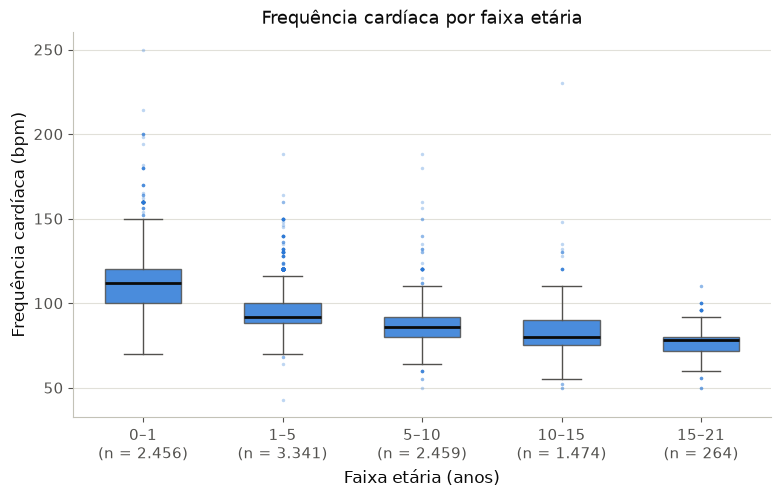

In [ ]:
fc_por_faixa_dados = [df_limpo.loc[faixa_etaria == f, 'FC'].dropna() for f in ROTULOS_FAIXAS]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(fc_por_faixa_dados, widths=0.55, patch_artist=True,
                tick_labels=[f'{f}\n(n = {fmt_n(len(d))})' for f, d in zip(ROTULOS_FAIXAS, fc_por_faixa_dados)],
                medianprops=dict(color=TINTA, linewidth=2),
                whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                flierprops=dict(marker='o', markersize=2.5, alpha=0.3,
                                markerfacecolor=COR_UNICA, markeredgewidth=0))
for caixa in bp['boxes']:
    caixa.set(facecolor=COR_UNICA, alpha=0.85, edgecolor=TINTA_2)
ax.set_xlabel('Faixa etária (anos)')
ax.set_ylabel('Frequência cardíaca (bpm)')
ax.set_title('Frequência cardíaca por faixa etária')
ax.grid(axis='x', visible=False)
salvar(fig, 'fc_por_faixa_etaria')

#### Interpretação
Boxplot por faixa etária: resume a queda da FC com a idade sem o excesso de pontos do
gráfico de dispersão. O n de cada faixa vai no rótulo para o leitor saber o peso de cada caixa.

In [6]:
# Mediana e quartis (e não média e desvio) porque a FC é assimétrica e tem valores extremos.
fc_por_faixa = (df_limpo.groupby(faixa_etaria, observed=True)['FC']
                .agg(n='count', Q1=lambda s: s.quantile(0.25), mediana='median',
                     Q3=lambda s: s.quantile(0.75))
                .round(1).reset_index().rename(columns={'IDADE': 'faixa etária (anos)'}))
display(fc_por_faixa)
exportar(fc_por_faixa, 'fc_por_faixa')

,faixa etária (anos),n,Q1,mediana,Q3
0,0–1,2456,100.0,112.0,120.0
1,1–5,3341,88.0,92.0,100.0
2,5–10,2459,80.0,86.0,92.0
3,10–15,1474,75.0,80.0,90.0
4,15–21,264,72.0,78.0,80.0


In [7]:
# Spearman, e não Pearson: a relação entre FC e idade não é necessariamente linear (a
# queda é mais rápida nos primeiros anos) e as duas variáveis são assimétricas. Spearman
# usa a ordem dos valores, então mede qualquer relação que só suba ou só desça.
par = df_limpo[['IDADE', 'FC']].dropna()
rho_fc_idade, p_fc_idade = spearmanr(par['IDADE'], par['FC'])
print(f'Spearman FC x IDADE: rho = {num(rho_fc_idade, 3)}, {p_txt(p_fc_idade)} (n = {fmt_n(len(par))})')

Spearman FC x IDADE: rho = -0,693, p < 0,001 (n = 9.994)


## Parte 2 – Cada variável contra o alvo

Um só teste para tudo: **qui-quadrado**. As regras:

- **Numéricas:** viram quartis, e o qui-quadrado compara a % de Anormal entre as quatro faixas.
- **Categorias raras:** categorias com menos de 30 registros são agrupadas em "Outras". Se "Outras" continuar com menos de 30, ou se uma variável binária tiver menos de 30 casos positivos, ela fica fora do teste e aparece na tabela como "n insuficiente". Isso também evita frequências esperadas abaixo de 5, que deixariam o qui-quadrado impreciso.
- **Resumo do efeito:** "% Anormal: maior = a% vs menor = b%", o mesmo formato para todas as variáveis.
- **Relações não monotônicas:** nas numéricas, a maior e a menor % de Anormal nem sempre estão nos quartis extremos. Na PA sistólica, por exemplo, o resumo compara Q1 com Q2. Quando isso acontece, a coluna "observação" avisa, e a interpretação deve considerar que a % de Anormal não sobe nem desce de forma contínua com o valor.
- **Quartis fundidos:** quando muitos valores se repetem (PA diastólica quase sempre 60 ou 70), dois quartis têm o mesmo limite e viram uma faixa só, rotulada "Q1–Q2".

In [ ]:
def em_quartis(serie, casas=1):
    """Divide uma numérica em quartis rotulados com os valores observados em cada faixa.

    Com muitos valores repetidos (ex.: PA diastólica quase sempre 60 ou 70), dois quartis
    podem ter o mesmo limite e se fundir numa faixa só; o rótulo mostra isso ("Q1–Q2").
    """
    # retbins devolve os limites exatos; os dos rótulos do qcut vêm arredondados.
    q, bordas = pd.qcut(serie, q=4, duplicates='drop', retbins=True)
    limites = serie.groupby(q, observed=True).agg(['min', 'max'])
    # Cada quartil pertence à primeira faixa cujo limite superior alcança o seu. isclose
    # evita que diferenças de arredondamento separem limites que são iguais.
    cortes = serie.quantile([0.25, 0.5, 0.75, 1.0]).to_numpy()
    direitas = bordas[1:]
    faixa_do_quartil = [next(j for j, d in enumerate(direitas) if c <= d or np.isclose(c, d))
                        for c in cortes]
    rotulos = []
    for j, (lo, hi) in enumerate(zip(limites['min'], limites['max'])):
        cobertos = [k + 1 for k, jj in enumerate(faixa_do_quartil) if jj == j]
        nome = f'Q{cobertos[0]}' if len(cobertos) == 1 else f'Q{cobertos[0]}–Q{cobertos[-1]}'
        rotulos.append(f'{nome} ({num(lo, casas)}–{num(hi, casas)})')
    nota = '' if len(limites) == 4 else 'valores repetidos: quartis com o mesmo limite foram fundidos'
    return q.cat.rename_categories(rotulos), nota


def testar(serie, nome, tipo, casas=1, mostrar=True):
    """Qui-quadrado entre uma variável e o alvo, com o mesmo resumo de efeito para todas.

    tipo: 'categórica', 'binária' ou 'numérica (quartis)'. Usa só as linhas sem nulo.
    """
    obs = []
    x = serie
    if tipo == 'numérica (quartis)':
        x, nota = em_quartis(serie, casas)
        if nota:
            obs.append(nota)
    elif tipo == 'binária':
        x = serie.map({1: 'sim', 0: 'não'})
    dados = pd.DataFrame({'x': x, 'alvo': df_limpo.loc[serie.index, ALVO]}).dropna()

    if tipo == 'binária' and (dados['x'] == 'sim').sum() < N_MIN:
        n_sim = int((dados['x'] == 'sim').sum())
        return {'variável': nome, 'tipo': tipo, 'teste': 'não testada', 'n': len(dados), 'p': np.nan,
                'resumo do efeito': f'n insuficiente (apenas {n_sim} casos "sim")',
                'diferença (p.p.)': np.nan, 'observação': 'menos de 30 casos positivos', 'tabela': None}

    if tipo == 'categórica':
        contagem = dados['x'].value_counts()
        raras = list(contagem[contagem < N_MIN].index)
        if raras:
            dados['x'] = dados['x'].astype(object).where(~dados['x'].isin(raras), 'Outras')
            n_outras = int((dados['x'] == 'Outras').sum())
            nomes = ', '.join(str(r) for r in raras)
            if n_outras < N_MIN:
                dados = dados[dados['x'] != 'Outras']
                obs.append(f'{nomes} (n = {n_outras}) fora do teste: n insuficiente')
            else:
                obs.append(f'{nomes} agrupadas em "Outras" (n = {n_outras})')

    tabela = pd.crosstab(dados['x'], dados['alvo'])[['Normal', 'Anormal']]
    _, p, _, esperadas = chi2_contingency(tabela)
    n_cat = tabela.sum(axis=1)
    pct = tabela['Anormal'] / n_cat * 100
    maior, menor = pct.idxmax(), pct.idxmin()
    if (esperadas < 5).any():
        obs.append(f'frequência esperada < 5 em {int((esperadas < 5).sum())} célula(s)')
    # Nas numéricas, o resumo "maior vs menor" só compara as faixas extremas se a relação for
    # monotônica (a % de Anormal só sobe ou só desce). Quando não é, isso fica registrado.
    if tipo == 'numérica (quartis)' and {maior, menor} != {tabela.index[0], tabela.index[-1]}:
        obs.append('relação não monotônica: maior e menor % de Anormal fora das faixas extremas')

    resultado = {
        'variável': nome, 'tipo': tipo, 'teste': 'qui-quadrado', 'n': int(n_cat.sum()), 'p': p,
        'resumo do efeito': f'% Anormal: {maior} = {num(pct[maior])}% vs {menor} = {num(pct[menor])}%',
        'diferença (p.p.)': round(pct[maior] - pct[menor], 1),
        'observação': '; '.join(obs),
        'tabela': tabela.assign(n=n_cat, **{'% Anormal': pct.round(1)}),
    }
    if mostrar:
        print(f'\n{nome} ({tipo}): qui-quadrado {p_txt(p)}, n = {fmt_n(n_cat.sum())}')
        display(resultado['tabela'])
        if obs:
            print('Obs.: ' + '; '.join(obs))
    return resultado

In [9]:
# Categóricas: tabela de contingência, % de Anormal e n por categoria, e o qui-quadrado.
CATEGORICAS = {
    'SOPRO': df_limpo['SOPRO'],
    'B2': df_limpo['B2'],
    'PULSOS': df_limpo['PULSOS'],
    'MOTIVO1': MOTIVO1,
    'SEXO': df_limpo['SEXO'],
    'PPA (recalculada)': PPA,
}
resultados = {nome: testar(serie, nome, 'categórica') for nome, serie in CATEGORICAS.items()}


SOPRO (categórica): qui-quadrado p < 0,001, n = 10.592


alvo,Normal,Anormal,n,% Anormal
x,,,,
Ausente,5940,663,6603,10.0
Contínuo,9,29,38,76.3
Sistólico,163,3788,3951,95.9


Obs.: Diastólico, Sistólico e diastólico (n = 10) fora do teste: n insuficiente

B2 (categórica): qui-quadrado p < 0,001, n = 10.595


alvo,Normal,Anormal,n,% Anormal
x,,,,
Desdobramento fixo,15,123,138,89.1
Hiperfonética,5,243,248,98.0
Normal,6079,4000,10079,39.7
Outro,9,56,65,86.2
Única,2,63,65,96.9



PULSOS (categórica): qui-quadrado p < 0,001, n = 10.566


alvo,Normal,Anormal,n,% Anormal
x,,,,
Amplos,6,37,43,86.0
Femorais diminuídos,2,33,35,94.3
Normais,6085,4372,10457,41.8
Outro,8,23,31,74.2


... (2 outputs left out)


SEXO (categórica): qui-quadrado p = 0,070, n = 10.134


alvo,Normal,Anormal,n,% Anormal
x,,,,
F,2362,1774,4136,42.9
M,3535,2463,5998,41.1



PPA (recalculada) (categórica): qui-quadrado p = 0,010, n = 2.546


alvo,Normal,Anormal,n,% Anormal
x,,,,
Normal,1365,760,2125,35.8
Pré-hipertensão,143,69,212,32.5
HAS estágio 1,105,64,169,37.9
HAS estágio 2,16,24,40,60.0


In [10]:
# Binárias (sintomas, motivos, indicadores de ausência e pa_medida): são muitas, então os
# resultados vão numa tabela só, com n e % de Anormal para "sim" e "não" e o p-valor.
BINARIAS = ([c for c in df_limpo if c.startswith('sint_') or c.startswith('motivo_')]
            + ['hda_ausente', 'pa_medida'])
linhas = []
for col in BINARIAS:
    r = testar(df_limpo[col], col, 'binária', mostrar=False)
    resultados[col] = r
    t = r['tabela']
    linhas.append({
        'variável': col,
        'n sim': int(t.loc['sim', 'n']) if t is not None else int((df_limpo[col] == 1).sum()),
        '% Anormal (sim)': t.loc['sim', '% Anormal'] if t is not None else np.nan,
        'n não': int(t.loc['não', 'n']) if t is not None else int((df_limpo[col] == 0).sum()),
        '% Anormal (não)': t.loc['não', '% Anormal'] if t is not None else np.nan,
        'p-valor': fmt_p(r['p']) if t is not None else 'n insuficiente',
    })
display(pd.DataFrame(linhas))

,variável,n sim,% Anormal (sim),n não,% Anormal (não),p-valor
0,motivo_ausente,100,50.0,10503,42.3,"0,146"
1,sint_assintomatico,6032,46.6,4571,36.8,"< 0,001"
2,sint_cianose,292,56.2,10311,42.0,"< 0,001"
3,sint_desmaio_tontura,185,28.1,10418,42.6,"< 0,001"
4,sint_dispneia,559,51.7,10044,41.8,"< 0,001"
5,sint_dor_precordial,509,32.2,10094,42.9,"< 0,001"
6,sint_ganho_de_peso,98,34.7,10505,42.4,"0,151"
7,sint_outro,151,44.4,10452,42.3,"0,671"
8,sint_palpitacao,413,29.5,10190,42.9,"< 0,001"
9,motivo_cardiopatia_adquirida,82,54.9,10521,42.2,"0,028"


In [11]:
# Numéricas: primeiro o descritivo por classe (mediana e quartis, porque as distribuições
# são assimétricas), para o texto do relatório; depois o qui-quadrado sobre os quartis.
NUMERICAS = {'IDADE': 1, 'FC': 0, 'Peso': 1, 'Altura': 0, 'IMC': 1, 'PA SISTOLICA': 0, 'PA DIASTOLICA': 0}

partes = {}
for classe in ('Normal', 'Anormal'):
    sub = df_limpo.loc[df_limpo[ALVO] == classe, list(NUMERICAS)]
    partes[classe] = pd.DataFrame({'n': sub.count(), 'Q1': sub.quantile(0.25),
                                   'mediana': sub.median(), 'Q3': sub.quantile(0.75)})
descritivo = pd.concat(partes, axis=1).round(1)
display(descritivo)

for col, casas in NUMERICAS.items():
    resultados[col] = testar(df_limpo[col], col, 'numérica (quartis)', casas=casas)

Normal                      Anormal                     
                   n    Q1 mediana     Q3       n    Q1 mediana     Q3
IDADE           6113   1.8     4.8    9.3    4490   0.4     2.7    6.5
FC              5795  80.0    90.0  100.0    4199  88.0    98.0  110.0
Peso            5014  11.6    18.0   31.8    3723   6.0    13.0   21.0
Altura          4163  81.0   105.0  134.0    3105  59.0    89.0  115.0
IMC             3972  15.5    17.1   19.3    2941  14.6    16.3   18.1
PA SISTOLICA    2957  95.0   100.0  110.0    1627  90.0   100.0  110.0
PA DIASTOLICA   2953  60.0    60.0   70.0    1622  60.0    60.0   65.0


IDADE (numérica (quartis)): qui-quadrado p < 0,001, n = 10.603


alvo,Normal,Anormal,n,% Anormal
x,,,,
"Q1 (0,0–1,0)",1030,1622,2652,61.2
"Q2 (1,0–3,9)",1589,1062,2651,40.1
"Q3 (3,9–8,2)",1633,1016,2649,38.4
"Q4 (8,2–21,0)",1861,790,2651,29.8



FC (numérica (quartis)): qui-quadrado p < 0,001, n = 9.994


alvo,Normal,Anormal,n,% Anormal
x,,,,
Q1 (43–80),1898,751,2649,28.4
Q2 (81–92),1778,1022,2800,36.5
Q3 (93–100),1164,1058,2222,47.6
Q4 (102–250),955,1368,2323,58.9



Peso (numérica (quartis)): qui-quadrado p < 0,001, n = 8.737


... (6 outputs left out)

alvo,Normal,Anormal,n,% Anormal
x,,,,
Q1 (60–90),710,496,1206,41.1
Q2 (92–100),1364,656,2020,32.5
Q3 (103–110),554,299,853,35.1
Q4 (111–180),329,176,505,34.9



PA DIASTOLICA (numérica (quartis)): qui-quadrado p = 0,005, n = 4.575


alvo,Normal,Anormal,n,% Anormal
x,,,,
F1 (23–60),1941,1141,3082,37.0
F2 (62–70),741,361,1102,32.8
F3 (72–120),271,120,391,30.7


Obs.: valores repetidos: 3 faixas em vez de 4


In [12]:
# Tabela-resumo única. Com ~10 mil pacientes, quase qualquer diferença dá p < 0,05: o
# p-valor só diz que a diferença provavelmente não é acaso, não que ela é grande. Por
# isso a tabela é ordenada pelo tamanho da diferença (em pontos percentuais de Anormal),
# e é esse tamanho que deve guiar a interpretação.
resumo = pd.DataFrame([{k: v for k, v in r.items() if k != 'tabela'} for r in resultados.values()])
resumo['p-valor'] = [fmt_p(p) if pd.notna(p) else '—' for p in resumo['p']]
resumo['significativo (α = 0,05)'] = ['sim' if p < ALFA else 'não' if pd.notna(p) else '—' for p in resumo['p']]
resumo = (resumo.sort_values('diferença (p.p.)', ascending=False, na_position='last')
          [['variável', 'tipo', 'teste', 'n', 'p-valor', 'significativo (α = 0,05)',
            'resumo do efeito', 'diferença (p.p.)', 'observação']]
          .reset_index(drop=True))
display(resumo)
exportar(resumo, 'bivariada_resumo')

,variável,tipo,teste,n,p-valor,"significativo (α = 0,05)",resumo do efeito,diferença (p.p.),observação
0,SOPRO,categórica,qui-quadrado,10592,"< 0,001",sim,"% Anormal: Sistólico = 95,9% vs Ausente = 10,0%",85.8,"Diastólico, Sistólico e diastólico (n = 10) fora do teste: n insuficiente"
1,B2,categórica,qui-quadrado,10595,"< 0,001",sim,"% Anormal: Hiperfonética = 98,0% vs Normal = 39,7%",58.3,
2,PULSOS,categórica,qui-quadrado,10566,"< 0,001",sim,"% Anormal: Femorais diminuídos = 94,3% vs Normais = 41,8%",52.5,Diminuídos (n = 13) fora do teste: n insuficiente
3,MOTIVO1,categórica,qui-quadrado,10503,"< 0,001",sim,"% Anormal: Cardiopatia já estabelecida = 70,9% vs Parecer cardiológico = 25,2%",45.7,
4,motivo_sopro,binária,qui-quadrado,10603,"< 0,001",sim,"% Anormal: sim = 76,4% vs não = 33,8%",42.6,
5,Peso,numérica (quartis),qui-quadrado,8737,"< 0,001",sim,"% Anormal: Q1 (1,2–9,0) = 63,1% vs Q4 (27,1–118,0) = 28,3%",34.8,
6,motivo_cardiopatia_congenita,binária,qui-quadrado,10603,"< 0,001",sim,"% Anormal: sim = 72,9% vs não = 39,6%",33.3,
7,Altura,numérica (quartis),qui-quadrado,7268,"< 0,001",sim,"% Anormal: Q1 (40–70) = 62,0% vs Q4 (128–198) = 28,9%",33.1,
8,motivo_cardiopatia_ja_estabelecida,binária,qui-quadrado,10603,"< 0,001",sim,"% Anormal: sim = 70,9% vs não = 39,4%",31.5,
9,IDADE,numérica (quartis),qui-quadrado,10603,"< 0,001",sim,"% Anormal: Q1 (0,0–1,0) = 61,2% vs Q4 (8,2–21,0) = 29,8%",31.4,


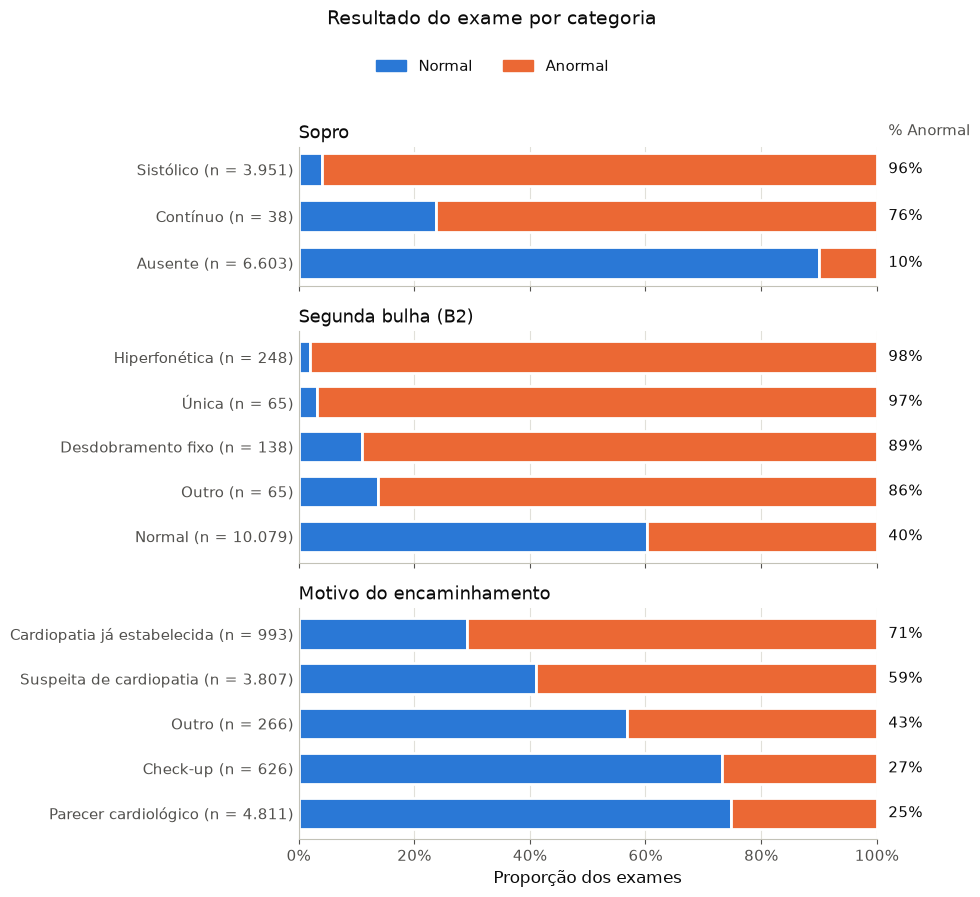

In [13]:
# Barras 100% empilhadas para as três categóricas mais importantes clinicamente. Cada
# barra soma 100%, então categorias de tamanhos muito diferentes ficam comparáveis; o n
# vai no rótulo e a % de Anormal à direita, para não depender só da cor.
PAINEIS = [('SOPRO', 'Sopro'), ('B2', 'Segunda bulha (B2)'), ('MOTIVO1', 'Motivo do encaminhamento')]
tabelas_painel = [resultados[v]['tabela'].sort_values('% Anormal') for v, _ in PAINEIS]

fig, eixos = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                          gridspec_kw={'height_ratios': [len(t) for t in tabelas_painel]})
for ax, (_, titulo), t in zip(eixos, PAINEIS, tabelas_painel):
    y = np.arange(len(t))
    pct_anormal = t['% Anormal']
    ax.barh(y, 100 - pct_anormal, color=COR['Normal'], edgecolor='white', linewidth=2, height=0.7)
    ax.barh(y, pct_anormal, left=100 - pct_anormal, color=COR['Anormal'],
            edgecolor='white', linewidth=2, height=0.7)
    ax.set_yticks(y, [f'{c} (n = {fmt_n(n)})' for c, n in zip(t.index, t['n'])])
    for yi, v in zip(y, pct_anormal):
        ax.text(102, yi, f'{num(v, 0)}%', va='center', fontsize=11, color=TINTA)
    ax.set_title(titulo, loc='left')
    ax.set_xlim(0, 100)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
eixos[0].text(102, len(tabelas_painel[0]) - 0.35, '% Anormal', fontsize=11, color=TINTA_2, va='bottom')
eixos[-1].xaxis.set_major_formatter(PercentFormatter())
eixos[-1].set_xlabel('Proporção dos exames')
fig.legend(handles=[Patch(color=COR['Normal'], label='Normal'), Patch(color=COR['Anormal'], label='Anormal')],
           loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.955))
fig.suptitle('Resultado do exame por categoria', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.93))
salvar(fig, 'bivariada_categoricas')

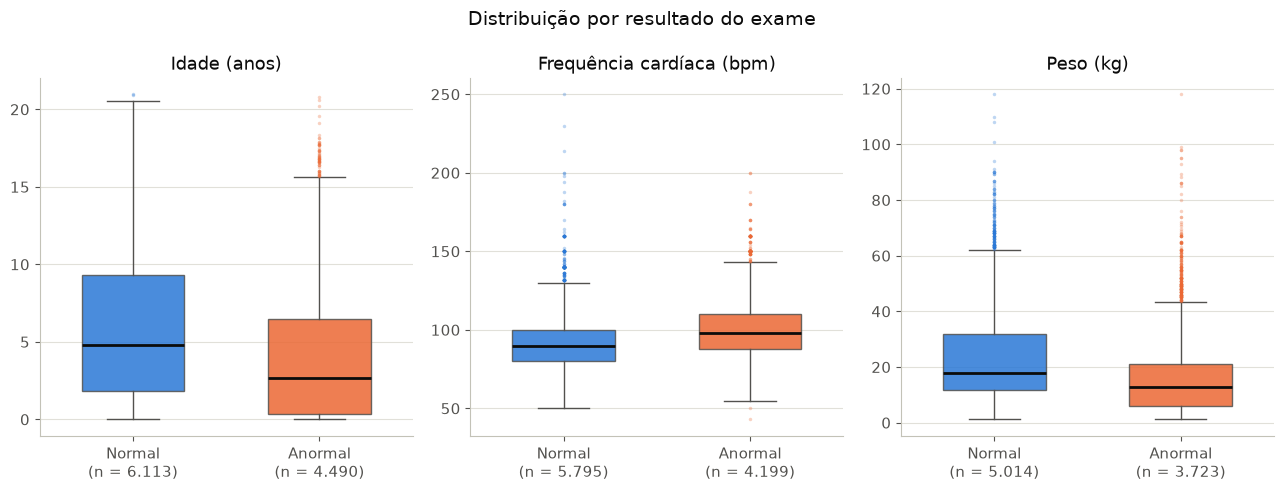

In [14]:
# Boxplots por classe para as três numéricas de maior interesse: mostram posição e
# dispersão de cada classe lado a lado, sem a perda de informação dos quartis.
PAINEIS_NUM = [('IDADE', 'Idade (anos)'), ('FC', 'Frequência cardíaca (bpm)'), ('Peso', 'Peso (kg)')]

fig, eixos = plt.subplots(1, 3, figsize=(13, 5))
for ax, (col, rotulo) in zip(eixos, PAINEIS_NUM):
    grupos = [df_limpo.loc[df_limpo[ALVO] == c, col].dropna() for c in ('Normal', 'Anormal')]
    bp = ax.boxplot(grupos, widths=0.55, patch_artist=True,
                    tick_labels=[f'{c}\n(n = {fmt_n(len(g))})' for c, g in zip(('Normal', 'Anormal'), grupos)],
                    medianprops=dict(color=TINTA, linewidth=2),
                    whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                    flierprops=dict(marker='o', markersize=2.5, alpha=0.3, markeredgewidth=0))
    for caixa, fliers, c in zip(bp['boxes'], bp['fliers'], ('Normal', 'Anormal')):
        caixa.set(facecolor=COR[c], alpha=0.85, edgecolor=TINTA_2)
        fliers.set_markerfacecolor(COR[c])
    ax.set_title(rotulo)
    ax.grid(axis='x', visible=False)
fig.suptitle('Distribuição por resultado do exame')
fig.tight_layout()
salvar(fig, 'bivariada_numericas')

## Parte 3 – A relação entre FC e o alvo é explicada pela idade?

A FC cai com a idade (Parte 1), e a proporção de Anormal também muda com a idade. Então a associação entre FC e alvo pode ser, em parte, só um reflexo da idade. Para separar os dois efeitos, comparamos cada criança apenas com as da mesma faixa etária.

In [15]:
# fc_z_idade: quantos desvios-padrão a FC de cada criança está acima ou abaixo da média
# da própria faixa etária. Isso tira o efeito da idade: um bebê com FC alta para bebês e
# um adolescente com FC alta para adolescentes ficam com z parecido.
# É uma Series à parte, fora do df_limpo, porque aqui é só exploratória. No pipeline de
# modelagem, a média e o desvio de cada faixa devem ser calculados APENAS no conjunto de
# treino e aplicados ao teste; calculá-los na base inteira vazaria informação do teste.
grupo_fc = df_limpo.groupby(faixa_etaria, observed=True)['FC']
fc_z_idade = ((df_limpo['FC'] - grupo_fc.transform('mean')) / grupo_fc.transform('std')).rename('fc_z_idade')

# Mesmo teste da Parte 2 nas duas versões da FC, para a comparação ser direta.
r_fc = resultados['FC']
r_fc_z = testar(fc_z_idade, 'FC ajustada pela idade (z por faixa)', 'numérica (quartis)', casas=2)

comparacao = pd.DataFrame([
    {'versão da FC': 'FC bruta', 'p-valor': fmt_p(r_fc['p']),
     'diferença de % Anormal entre quartis (p.p.)': r_fc['diferença (p.p.)'], 'resumo': r_fc['resumo do efeito']},
    {'versão da FC': 'FC ajustada pela idade', 'p-valor': fmt_p(r_fc_z['p']),
     'diferença de % Anormal entre quartis (p.p.)': r_fc_z['diferença (p.p.)'], 'resumo': r_fc_z['resumo do efeito']},
])
display(comparacao)

# Critério: a associação "desapareceu" se deixar de ser significativa; "diminuiu bastante"
# se a diferença entre os quartis extremos cair para menos da metade; senão, persiste.
dif_bruta, dif_z = r_fc['diferença (p.p.)'], r_fc_z['diferença (p.p.)']
if r_fc_z['p'] >= ALFA:
    conclusao_fc = ('A associação entre FC e alvo desapareceu depois de ajustar pela idade: '
                    'ela era explicada pela idade.')
elif dif_z < dif_bruta / 2:
    conclusao_fc = (f'A associação diminuiu bastante depois de ajustar pela idade ({num(dif_bruta)} → '
                    f'{num(dif_z)} p.p.): boa parte dela era explicada pela idade.')
else:
    conclusao_fc = (f'A associação persiste depois de ajustar pela idade ({num(dif_bruta)} → '
                    f'{num(dif_z)} p.p.): a FC tem associação própria com o alvo.')
print(conclusao_fc)


FC ajustada pela idade (z por faixa) (numérica (quartis)): qui-quadrado p < 0,001, n = 9.994


alvo,Normal,Anormal,n,% Anormal
x,,,,
"Q1 (-4,32–-0,60)",1880,1128,3008,37.5
"Q2 (-0,57–-0,19)",1346,753,2099,35.9
"Q3 (-0,13–0,43)",1420,1167,2587,45.1
"Q4 (0,50–12,82)",1149,1151,2300,50.0


,versão da FC,p-valor,diferença de % Anormal entre quartis (p.p.),resumo
0,FC bruta,"< 0,001",30.5,"% Anormal: Q4 (102–250) = 58,9% vs Q1 (43–80) = 28,4%"
1,FC ajustada pela idade,"< 0,001",14.2,"% Anormal: Q4 (0,50–12,82) = 50,0% vs Q2 (-0,57–-0,19) = 35,9%"


A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade.


## Parte 4 – Evidências para as transformações

Aqui só se calcula e imprime. Nenhuma transformação é aplicada ao `df_limpo`: elas pertencem ao pipeline de modelagem, depois da divisão treino/teste.

,Peso,Altura,IMC,Idade
Peso,1.00,0.98,0.51,0.97
Altura,0.98,1.00,0.38,0.99
IMC,0.51,0.38,1.00,0.37
Idade,0.97,0.99,0.37,1.00


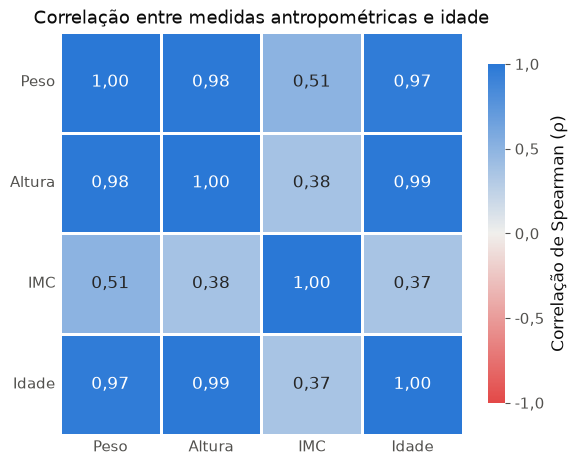

Redundantes (|ρ| ≥ 0,8): Peso e Altura, ρ = 0,98
Redundantes (|ρ| ≥ 0,8): Peso e Idade, ρ = 0,97
Redundantes (|ρ| ≥ 0,8): Altura e Idade, ρ = 0,99


In [16]:
# 1) Correlação entre as medidas antropométricas e a idade. Pares muito correlacionados
# (|ρ| ≥ 0,8) carregam quase a mesma informação, e manter os dois só adiciona redundância.
# Spearman pelos mesmos motivos da Parte 1 (assimetria e relação não necessariamente linear).
ANTROPO = {'Peso': 'Peso', 'Altura': 'Altura', 'IMC': 'IMC', 'IDADE': 'Idade'}
corr = df_limpo[list(ANTROPO)].corr(method='spearman').rename(index=ANTROPO, columns=ANTROPO)
display(corr.round(2))

# Escala divergente (vermelho = negativa, cinza = zero, azul = positiva) fixa de -1 a 1,
# para a cor significar o mesmo em qualquer figura de correlação.
divergente = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, vmin=-1, vmax=1, cmap=divergente, annot=corr.map(lambda v: num(v, 2)).to_numpy(),
            fmt='', annot_kws={'fontsize': 12}, linewidths=2, linecolor='white', square=True,
            cbar_kws={'label': 'Correlação de Spearman (ρ)', 'shrink': 0.8}, ax=ax)
barra = ax.collections[0].colorbar
barra.set_ticks([-1, -0.5, 0, 0.5, 1], labels=[num(v, 1) for v in (-1, -0.5, 0, 0.5, 1)])
ax.set_title('Correlação entre medidas antropométricas e idade')
ax.tick_params(length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
salvar(fig, 'correlacao_antropometricas')

# Pares redundantes, usados na justificativa da tabela de transformações.
pares_redundantes = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.index)
                     for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.8]
for a, b, r in pares_redundantes:
    print(f'Redundantes (|ρ| ≥ 0,8): {a} e {b}, ρ = {num(r, 2)}')

,assimetria
IDADE,0.79
FC,1.27
Peso,1.44
Altura,0.22
IMC,1.22
PA SISTOLICA,1.20
PA DIASTOLICA,0.90


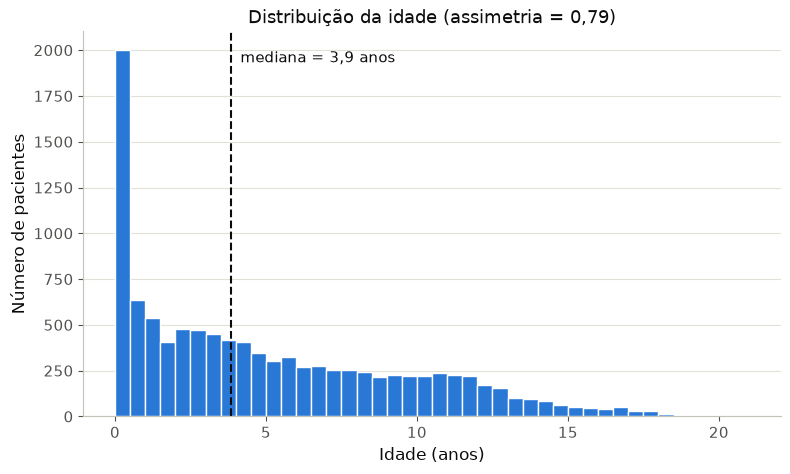

In [17]:
# 2) Assimetria. Acima de 1 em módulo, a distribuição é fortemente assimétrica: médias e
# modelos sensíveis à escala ficam dominados pela cauda, o que justifica log ou faixas.
assimetria = df_limpo[list(NUMERICAS)].skew().round(2).rename('assimetria')
display(assimetria.to_frame())

idade = df_limpo['IDADE']
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(idade, bins=np.arange(0, 21.5, 0.5), color=COR_UNICA, edgecolor='white', linewidth=1)
ax.axvline(idade.median(), color=TINTA, linestyle='--', linewidth=1.5)
ax.text(idade.median() + 0.3, ax.get_ylim()[1] * 0.95, f'mediana = {num(idade.median())} anos',
        va='top', fontsize=11, color=TINTA)
ax.set_xlabel('Idade (anos)')
ax.set_ylabel('Número de pacientes')
ax.set_title(f'Distribuição da idade (assimetria = {num(assimetria["IDADE"], 2)})')
ax.grid(axis='x', visible=False)
salvar(fig, 'hist_idade')

In [18]:
# 3) Categorias raras: uma coluna one-hot para uma categoria com poucos casos quase nunca
# vale 1, o modelo não aprende nada com ela e ainda ganha uma variável a mais.
for col in ['PULSOS', 'B2', 'SOPRO']:
    contagem = df_limpo[col].value_counts(dropna=False)
    display(pd.DataFrame({'n': contagem, '%': (contagem / len(df_limpo) * 100).round(1)}).rename_axis(col))

,n,%
PULSOS,,
Normais,10457,98.6
Amplos,43,0.4
Femorais diminuídos,35,0.3
Outro,31,0.3
NaN,24,0.2
Diminuídos,13,0.1


,n,%
B2,,
Normal,10079,95.1
Hiperfonética,248,2.3
Desdobramento fixo,138,1.3
Outro,65,0.6
Única,65,0.6
NaN,8,0.1


,n,%
SOPRO,,
Ausente,6603,62.3
Sistólico,3951,37.3
Contínuo,38,0.4
Diastólico,7,0.1
Sistólico e diastólico,3,0.0
NaN,1,0.0


In [ ]:
# 4) Proporção do alvo. Um desbalanceamento leve não pede reamostragem, só divisão
# treino/teste estratificada pelo alvo.
proporcao_alvo = (df_limpo[ALVO].value_counts(normalize=True) * 100).round(1)
display(proporcao_alvo.to_frame('%'))

,%
NORMAL X ANORMAL,
Normal,57.7
Anormal,42.3


In [20]:
# 5) Tabela de transformações propostas. As justificativas usam os números calculados
# acima, para o relatório citar a evidência de cada decisão.
fc_medianas = fc_por_faixa.set_index('faixa etária (anos)')['mediana']
par_pa = df_limpo[['IDADE', 'PA SISTOLICA']].dropna()
rho_pas_idade = spearmanr(par_pa['IDADE'], par_pa['PA SISTOLICA'])[0]
sexo = df_limpo['SEXO'].value_counts()
ppa_n = PPA.value_counts().reindex(PPA.cat.categories)
pulsos = df_limpo['PULSOS'].value_counts()
pct_pulsos_normais = pulsos['Normais'] / pulsos.sum() * 100
raras_sopro = [c for c, n in df_limpo['SOPRO'].value_counts().items() if n < N_MIN]
raras_b2 = [c for c, n in df_limpo['B2'].value_counts().items() if n < N_MIN]


def intensidade(assim):
    """Convenção usual: |assimetria| < 0,5 leve, 0,5–1 moderada, > 1 forte."""
    return 'leve' if abs(assim) < 0.5 else 'moderada' if abs(assim) <= 1 else 'forte'


# Peso/Altura/IMC: sai quem é redundante com a IDADE (|ρ| ≥ 0,8); o IMC combina peso e altura.
redundantes_idade = [c for c in ('Peso', 'Altura') if abs(corr.loc[c, 'Idade']) >= 0.8]
manter = [c for c in ('Peso', 'Altura', 'IMC') if c not in redundantes_idade]
texto_corr = '; '.join(f'{a}–{b}: ρ = {num(r, 2)}' for a, b, r in pares_redundantes) or 'nenhum par com |ρ| ≥ 0,8'

nulos = (df_limpo[list(NUMERICAS) + ['PULSOS', 'B2', 'SOPRO', 'SEXO', 'PPA_calc']]
         .isna().mean().mul(100).round(1))
nulos = nulos[nulos > 0].sort_values(ascending=False)

# numero de episodios x colunas de sintomas, para a linha dessa coluna na tabela.
colunas_sint = [c for c in df_limpo if c.startswith('sint_')]
episodios_iguais = df_limpo['numero de episodios'] == df_limpo[colunas_sint].sum(axis=1)
n_assintomaticos = int(df_limpo['sint_assintomatico'].sum())
texto_nulos = ', '.join(f'{c} {num(v)}%' for c, v in nulos.items())

transformacoes = pd.DataFrame([
    {'variável': 'NORMAL X ANORMAL e SEXO', 'transformação proposta': 'binária 0/1',
     'justificativa': (f'Duas categorias cada: alvo Normal {num(proporcao_alvo["Normal"])}% / '
                       f'Anormal {num(proporcao_alvo["Anormal"])}%; SEXO M = {fmt_n(sexo["M"])}, '
                       f'F = {fmt_n(sexo["F"])}.')},
    {'variável': 'SOPRO e B2', 'transformação proposta': 'one-hot',
     'justificativa': (f'Nominais sem ordem (SOPRO: {df_limpo["SOPRO"].nunique()} categorias; '
                       f'B2: {df_limpo["B2"].nunique()}); one-hot não impõe uma ordem inexistente. '
                       f'Categorias com n < 30 agrupadas antes: SOPRO {", ".join(raras_sopro) or "nenhuma"}; '
                       f'B2 {", ".join(raras_b2) or "nenhuma"}.')},
    {'variável': 'PULSOS', 'transformação proposta': 'agregação Normal/Alterado + binária',
     'justificativa': (f'{num(pct_pulsos_normais)}% dos registros são "Normais"; as outras '
                       f'{len(pulsos) - 1} categorias somam {fmt_n(pulsos.drop("Normais").sum())} casos, '
                       f'poucos demais para colunas próprias.')},
    {'variável': 'PPA (recalculada)', 'transformação proposta':
         'ordinal (Normal < Pré-hipertensão < HAS estágio 1 < HAS estágio 2)',
     'justificativa': ('Categorias com ordem clínica crescente; n por nível: '
                       + ', '.join(f'{c} {fmt_n(n)}' for c, n in ppa_n.items())
                       + f'. {num(PPA.isna().mean() * 100)}% nulos (sem PA medida).')},
    {'variável': 'FC e PA', 'transformação proposta': 'z-score por faixa etária',
     'justificativa': (f'Dependem da idade: FC x IDADE ρ = {num(rho_fc_idade, 2)} (mediana da FC de '
                       f'{num(fc_medianas.iloc[0], 0)} bpm aos 0–1 ano a {num(fc_medianas.iloc[-1], 0)} bpm aos '
                       f'15–21); PAS x IDADE ρ = {num(rho_pas_idade, 2)}. O z por faixa compara cada '
                       f'criança com as da mesma idade. {conclusao_fc}')},
    {'variável': 'Peso, Altura e IMC', 'transformação proposta':
         f'manter apenas os não redundantes: {", ".join(manter)} (além da IDADE)',
     'justificativa': (f'Pares com |ρ| ≥ 0,8: {texto_corr}. '
                       f'IMC x Idade: ρ = {num(corr.loc["IMC", "Idade"], 2)}.')},
    {'variável': 'IDADE', 'transformação proposta': 'log(1 + idade) ou faixas etárias',
     'justificativa': (f'Assimetria {intensidade(assimetria["IDADE"])} ({num(assimetria["IDADE"], 2)}), '
                       f'com cauda à direita; mediana de '
                       f'{num(df_limpo["IDADE"].median())} anos, com '
                       f'{num((df_limpo["IDADE"] < 1).mean() * 100)}% dos pacientes abaixo de 1 ano.')},
    {'variável': 'Numéricas', 'transformação proposta': 'padronização z-score ajustada só no treino',
     'justificativa': (f'Escalas muito diferentes (ex.: Peso até {num(df_limpo["Peso"].max(), 0)} kg, '
                       f'FC até {num(df_limpo["FC"].max(), 0)} bpm); média e desvio vindos só do treino '
                       'evitam vazamento de informação do teste.')},
    {'variável': 'Nulos restantes', 'transformação proposta':
         'imputação por mediana (numéricas) ou moda (categóricas) após a divisão treino/teste',
     'justificativa': (f'Ainda há nulos: {texto_nulos}. A mediana resiste à assimetria. A ausência de PA '
                       'não é aleatória (etapa 8 da limpeza), então pa_medida acompanha a imputação. '
                       f'Na PPA_calc, com {num(PPA.isna().mean() * 100)}% de nulos, a moda rotularia quase '
                       'todos como "Normal": ali a ausência deve virar uma categoria própria ("sem PA").')},
    {'variável': 'PPA_PAS_calc, PPA_PAD_calc e z_altura', 'transformação proposta': 'remover',
     'justificativa': ('Colunas intermediárias do cálculo da PPA: a PPA_calc já é, por definição, a pior '
                       'classificação entre PAS e PAD, e a z_altura só serviu para classificar a pressão '
                       '(é função de Altura, IDADE e SEXO, que já estão na base).')},
    {'variável': 'numero de episodios', 'transformação proposta': 'remover',
     'justificativa': (f'Veio da primeira versão da limpeza. Coincide com a soma das colunas sint_* em '
                       f'{num(episodios_iguais.mean() * 100, 2)}% das linhas e conta "Assintomático" como '
                       f'episódio ({fmt_n(n_assintomaticos)} pacientes); sint_* e hda_ausente já carregam '
                       'essa informação.')},
    {'variável': 'ID', 'transformação proposta': 'remover',
     'justificativa': (f'Identificador sem informação clínica ({fmt_n(df_limpo["ID"].nunique())} valores '
                       f'únicos em {fmt_n(len(df_limpo))} linhas). grupo_paciente também sai do modelo: '
                       'serve só para a divisão treino/teste por paciente.')},
])
display(transformacoes)
exportar(transformacoes, 'transformacoes')

,variável,transformação proposta,justificativa
0,NORMAL X ANORMAL e SEXO,binária 0/1,"Duas categorias cada: alvo Normal 57,7% / Anormal 42,3%; SEXO M = 5.998, F = 4.136."
1,SOPRO e B2,one-hot,"Nominais sem ordem (SOPRO: 5 categorias; B2: 5); one-hot não impõe uma ordem inexistente. Categorias com n < 30 agrupadas antes: SOPRO Diastólico, Sistólico e diastólico; B2 nenhuma."
2,PULSOS,agregação Normal/Alterado + binária,"98,8% dos registros são ""Normais""; as outras 4 categorias somam 122 casos, poucos demais para colunas próprias."
3,PPA (recalculada),ordinal (Normal < Pré-hipertensão < HAS estágio 1 < HAS estágio 2),"Categorias com ordem clínica crescente; n por nível: Normal 2.125, Pré-hipertensão 212, HAS estágio 1 169, HAS estágio 2 40. 76,0% nulos (sem PA medida)."
4,FC e PA,z-score por faixa etária,"Dependem da idade: FC x IDADE ρ = -0,69 (mediana da FC de 112 bpm aos 0–1 ano a 78 bpm aos 15–21); PAS x IDADE ρ = 0,42. O z por faixa compara cada criança com as da mesma idade. A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade."
5,"Peso, Altura e IMC",manter apenas os não redundantes: IMC (além da IDADE),"Pares com |ρ| ≥ 0,8: Peso–Altura: ρ = 0,98; Peso–Idade: ρ = 0,97; Altura–Idade: ρ = 0,99. IMC x Idade: ρ = 0,37."
6,IDADE,log(1 + idade) ou faixas etárias,"Assimetria moderada (0,79), com cauda à direita; mediana de 3,9 anos, com 24,9% dos pacientes abaixo de 1 ano."
7,Numéricas,padronização z-score ajustada só no treino,"Escalas muito diferentes (ex.: Peso até 118 kg, FC até 250 bpm); média e desvio vindos só do treino evitam vazamento de informação do teste."
8,Nulos restantes,imputação por mediana (numéricas) ou moda (categóricas) após a divisão treino/teste,"Ainda há nulos: PPA_calc 76,0%, PA DIASTOLICA 56,9%, PA SISTOLICA 56,8%, IMC 34,8%, Altura 31,5%, Peso 17,6%, FC 5,7%, SEXO 4,4%, PULSOS 0,2%, B2 0,1%. A mediana resiste à assimetria. A ausência de PA não é aleatória (etapa 8 da limpeza), então pa_medida acompanha a imputação. Na PPA_calc, com 76,0% de nulos, a moda rotularia quase todos como ""Normal"": ali a ausência deve virar uma categoria própria (""sem PA"")."
9,ID,remover,Identificador sem informação clínica (10.603 valores únicos em 10.603 linhas). grupo_paciente também sai do modelo: serve só para a divisão treino/teste por paciente.


## Resumo dos achados

In [ ]:
# Resumo gerado a partir dos resultados, sem números digitados à mão: se os dados
# mudarem, o texto acompanha.
testadas = resumo[resumo['teste'] == 'qui-quadrado']
top = testadas.head(3)
print('PARTE 1 – FC x IDADE')
print(f'  A base bruta tinha {fora_faixa.sum()} pontos impossíveis (FC fora de 40–250 bpm ou idade fora de '
      f'0–21 anos), eliminados na limpeza. Na base limpa, a FC cai com a idade '
      f'(Spearman ρ = {num(rho_fc_idade, 2)}, {p_txt(p_fc_idade)}): mediana de '
      f'{num(fc_medianas.iloc[0], 0)} bpm aos 0–1 ano e {num(fc_medianas.iloc[-1], 0)} bpm aos 15–21.')
print('\nPARTE 2 – Variáveis x alvo')
print(f'  {(testadas["significativo (α = 0,05)"] == "sim").sum()} de {len(testadas)} variáveis testadas têm '
      'p < 0,05, o esperado com n grande. As maiores diferenças de % Anormal:')
for _, linha in top.iterrows():
    print(f'  - {linha["variável"]}: {linha["resumo do efeito"]} ({num(linha["diferença (p.p.)"])} p.p.)')
print('\nPARTE 3 – Confundimento FC x IDADE')
print(f'  {conclusao_fc}')
print('\nPARTE 4 – Transformações')
print(f'  Pares redundantes (|ρ| ≥ 0,8): {texto_corr}.')
print(f'  IDADE com assimetria {num(assimetria["IDADE"], 2)}; PULSOS com {num(pct_pulsos_normais)}% "Normais"; '
      f'alvo {num(proporcao_alvo["Normal"])}% Normal / {num(proporcao_alvo["Anormal"])}% Anormal '
      '(desbalanceamento leve, sem necessidade de reamostragem).')

PARTE 1 – FC x IDADE
  A base bruta tinha 173 pontos impossíveis (FC fora de 40–250 bpm ou idade fora de 0–21 anos), eliminados na limpeza. Na base limpa, a FC cai com a idade (Spearman ρ = -0,69, p < 0,001): mediana de 112 bpm aos 0–1 ano e 78 bpm aos 15–21.

PARTE 2 – Variáveis x alvo
  31 de 40 variáveis testadas têm p < 0,05, o esperado com n grande. As maiores diferenças de % Anormal:
  - SOPRO: % Anormal: Sistólico = 95,9% vs Ausente = 10,0% (85,8 p.p.)
  - B2: % Anormal: Hiperfonética = 98,0% vs Normal = 39,7% (58,3 p.p.)
  - PULSOS: % Anormal: Femorais diminuídos = 94,3% vs Normais = 41,8% (52,5 p.p.)

PARTE 3 – Confundimento FC x IDADE
  A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade.

PARTE 4 – Transformações
  Pares redundantes (|ρ| ≥ 0,8): Peso–Altura: ρ = 0,98; Peso–Idade: ρ = 0,97; Altura–Idade: ρ = 0,99.
  IDADE com assimetria 0,79; PULSOS com 98,8% "Normais"; alvo 57,7% Normal / 42,3% Anormal (desb